# TVAR fatigue tracking

Kalman-smoothed and RLS time-varying AR spectra vs the 4 s sliding-FFT baseline, per muscle.
Tuning matches each TVAR method's 10–90 % step response to the baseline's, then compares trend
SNR / roughness at that equal time resolution. See `docs/superpowers/specs/2026-09-24-tvar-emg-design.md`.

In [3]:
import time

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from emg.baseline import sliding_fft
from emg.evaluate import align_to, match_resolution, median_rise_time, track_stats
from emg.io import MUSCLES, extract_subject, load_trial, trials_for_muscle
from emg.preprocess import bandpass, standardize
from emg.synthetic import step_trial
from emg.tvar import run_tvar, select_order

SUBJECTS = [1]            # add subject numbers here; missing ones are unzipped on demand
for s in SUBJECTS:
    extract_subject(s)

# trials[muscle][subject][trial] -> Trial (prime-mover channel only)
trials = {m: {s: {n: load_trial(s, n) for n in trials_for_muscle(m)} for s in SUBJECTS} for m in MUSCLES}
for m in MUSCLES:
    print(f"{m:22s}", {s: {n: f"{tr.t[-1]:.0f}s" for n, tr in trials[m][s].items()} for s in SUBJECTS})

R_DELTOID_ANTERIOR     {1: {1: '96s', 9: '352s'}}
L_DELTOID_ANTERIOR     {1: {2: '112s', 10: '571s'}}
R_DELTOID_POSTERIOR    {1: {3: '813s', 11: '404s'}}
L_DELTOID_POSTERIOR    {1: {4: '700s', 12: '298s'}}
R_BICEPS_BRACHII       {1: {5: '179s'}}
L_BICEPS_BRACHII       {1: {6: '211s'}}
R_DELTOID_MEDIUS       {1: {7: '114s'}}
L_DELTOID_MEDIUS       {1: {8: '119s'}}


In [4]:
tr = trials["R_DELTOID_ANTERIOR"][SUBJECTS[0]][9]
run_tvar(tr, "kalman", 12, q=1e-8)                 # first call compiles (numba cache)
t_start = time.perf_counter()
run_tvar(tr, "kalman", 12, q=1e-8)
print(f"Kalman smoother, p=12, {len(tr.x)} samples: {time.perf_counter() - t_start:.1f} s (target <= 30 s)")

Kalman smoother, p=12, 443179 samples: 1.3 s (target <= 30 s)


In [5]:
ORDER = {}   # AR order per muscle: median of per-trial selections
for m in MUSCLES:
    ps = [select_order(standardize(bandpass(tr.x, tr.fs)), tr.fs)
          for s in SUBJECTS for tr in trials[m][s].values()]
    ORDER[m] = int(np.median(ps))
    print(f"{m:22s} per-trial p = {ps} -> p = {ORDER[m]}")

R_DELTOID_ANTERIOR     per-trial p = [16, 16] -> p = 16
L_DELTOID_ANTERIOR     per-trial p = [16, 22] -> p = 19
R_DELTOID_POSTERIOR    per-trial p = [16, 16] -> p = 16
L_DELTOID_POSTERIOR    per-trial p = [16, 16] -> p = 16
R_BICEPS_BRACHII       per-trial p = [14] -> p = 14
L_BICEPS_BRACHII       per-trial p = [14] -> p = 14
R_DELTOID_MEDIUS       per-trial p = [12] -> p = 12
L_DELTOID_MEDIUS       per-trial p = [14] -> p = 14


In [6]:
baseline = {m: {s: {n: sliding_fft(tr) for n, tr in trials[m][s].items()} for s in SUBJECTS} for m in MUSCLES}

In [7]:
GRIDS = {"kalman": ("q", np.logspace(-11, -3, 25)), "rls": ("tau", [0.25, 0.5, 1, 1.5, 2, 3, 4, 6, 8])}
STEP_AT = 30.0
step_trials = [step_trial(step_at=STEP_AT, seed=seed) for seed in (0, 1, 2)]

# Baseline response time, measured on a fine (50 ms) step grid so the 2 s step doesn't quantize it.
TARGET_RT = median_rise_time([sliding_fft(tr, step_s=0.05) for tr in step_trials], STEP_AT)
print(f"FFT baseline 10-90 % rise time: {TARGET_RT:.2f} s")

# RISE[method][p][value] -> rise time (s). Depends on the AR order, so computed per distinct order.
RISE = {method: {p: {v: median_rise_time([run_tvar(tr, method, p, **{key: v}) for tr in step_trials], STEP_AT)
                     for v in grid}
                 for p in sorted(set(ORDER.values()))}
        for method, (key, grid) in GRIDS.items()}

BEST = {m: {method: match_resolution(RISE[method][ORDER[m]], TARGET_RT) for method in GRIDS} for m in MUSCLES}
for m in MUSCLES:
    print(f"{m:22s} p={ORDER[m]:2d}",
          {meth: f"{v:.3g} (rise {RISE[meth][ORDER[m]][v]:.2f} s)" for meth, v in BEST[m].items()})

FFT baseline 10-90 % rise time: 2.95 s
R_DELTOID_ANTERIOR     p=16 {'kalman': '4.64e-09 (rise 2.95 s)', 'rls': '2 (rise 2.90 s)'}
L_DELTOID_ANTERIOR     p=19 {'kalman': '4.64e-09 (rise 2.75 s)', 'rls': '2 (rise 2.95 s)'}
R_DELTOID_POSTERIOR    p=16 {'kalman': '4.64e-09 (rise 2.95 s)', 'rls': '2 (rise 2.90 s)'}
L_DELTOID_POSTERIOR    p=16 {'kalman': '4.64e-09 (rise 2.95 s)', 'rls': '2 (rise 2.90 s)'}
R_BICEPS_BRACHII       p=14 {'kalman': '4.64e-09 (rise 3.15 s)', 'rls': '2 (rise 2.95 s)'}
L_BICEPS_BRACHII       p=14 {'kalman': '4.64e-09 (rise 3.15 s)', 'rls': '2 (rise 2.95 s)'}
R_DELTOID_MEDIUS       p=12 {'kalman': '4.64e-09 (rise 3.40 s)', 'rls': '2 (rise 2.95 s)'}
L_DELTOID_MEDIUS       p=14 {'kalman': '4.64e-09 (rise 3.15 s)', 'rls': '2 (rise 2.95 s)'}


In [8]:
# results[muscle][subject][trial][method] -> SpectralTrack, TVAR at the resolution-matched setting
results = {m: {s: {} for s in SUBJECTS} for m in MUSCLES}
for m in MUSCLES:
    for s in SUBJECTS:
        for n, tr in trials[m][s].items():
            results[m][s][n] = {"fft_baseline": baseline[m][s][n]}
            for method, (key, _) in GRIDS.items():
                results[m][s][n][f"tvar_{method}"] = run_tvar(tr, method, ORDER[m], **{key: BEST[m][method]})

In [9]:
def stats_for(m, method):
    """track_stats per trial of muscle m; TVAR is sampled at the baseline's window centres."""
    return [track_stats(by_method[method] if method == "fft_baseline"
                        else align_to(by_method[method], by_method["fft_baseline"]))
            for s in SUBJECTS for by_method in results[m][s].values()]


rows = []
for m in MUSCLES:
    for method in ("fft_baseline", "tvar_kalman", "tvar_rls"):
        stats = stats_for(m, method)
        rows.append({"muscle": m, "method": method, "n_trials": len(stats),
                     **{k: float(np.median([st[k] for st in stats])) for k in stats[0]}})
summary = pl.DataFrame(rows)
with pl.Config(tbl_rows=-1, tbl_cols=-1, float_precision=2, tbl_width_chars=200):
    print(summary)

shape: (24, 9)
┌─────────────────────┬──────────────┬──────────┬───────────┬─────────┬───────────┬───────────┬─────────┬───────────┐
│ muscle              ┆ method       ┆ n_trials ┆ mnf_slope ┆ mnf_snr ┆ mnf_rough ┆ mdf_slope ┆ mdf_snr ┆ mdf_rough │
│ ---                 ┆ ---          ┆ ---      ┆ ---       ┆ ---     ┆ ---       ┆ ---       ┆ ---     ┆ ---       │
│ str                 ┆ str          ┆ i64      ┆ f64       ┆ f64     ┆ f64       ┆ f64       ┆ f64     ┆ f64       │
╞═════════════════════╪══════════════╪══════════╪═══════════╪═════════╪═══════════╪═══════════╪═════════╪═══════════╡
│ R_DELTOID_ANTERIOR  ┆ fft_baseline ┆ 2        ┆ -4.01     ┆ 3.34    ┆ 2.74      ┆ -3.63     ┆ 3.41    ┆ 2.86      │
│ R_DELTOID_ANTERIOR  ┆ tvar_kalman  ┆ 2        ┆ -3.08     ┆ 2.58    ┆ 3.94      ┆ -4.09     ┆ 2.25    ┆ 7.04      │
│ R_DELTOID_ANTERIOR  ┆ tvar_rls     ┆ 2        ┆ -4.61     ┆ 2.64    ┆ 4.21      ┆ -5.07     ┆ 3.15    ┆ 4.57      │
│ L_DELTOID_ANTERIOR  ┆ fft_baseline ┆ 2 

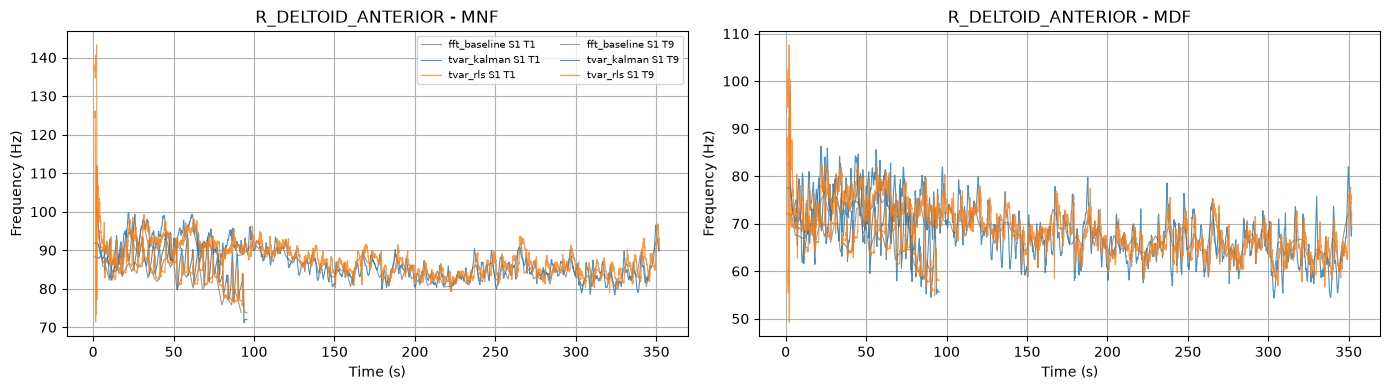

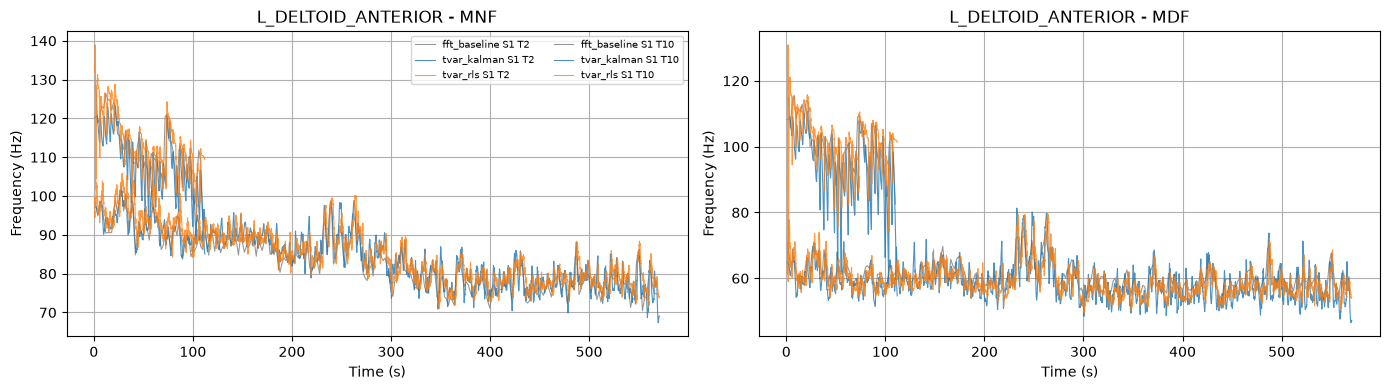

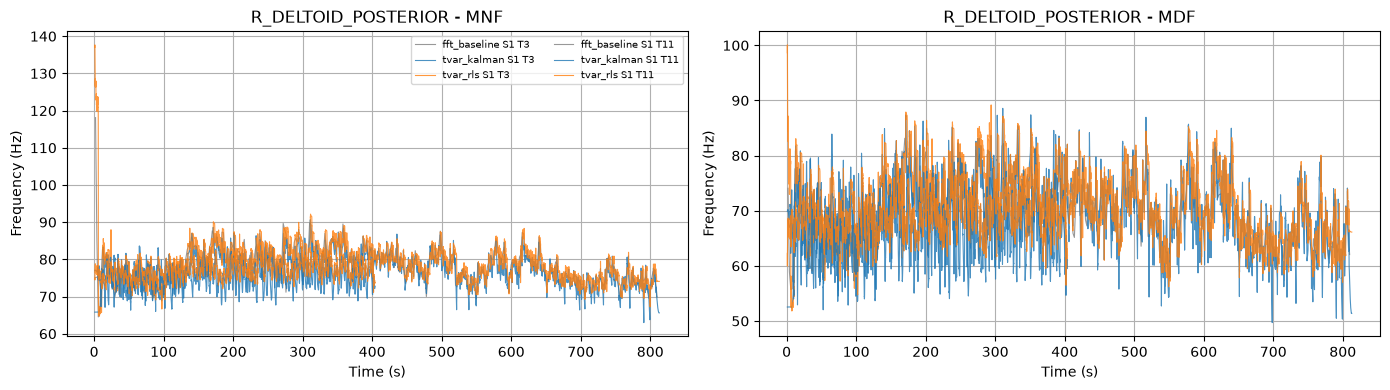

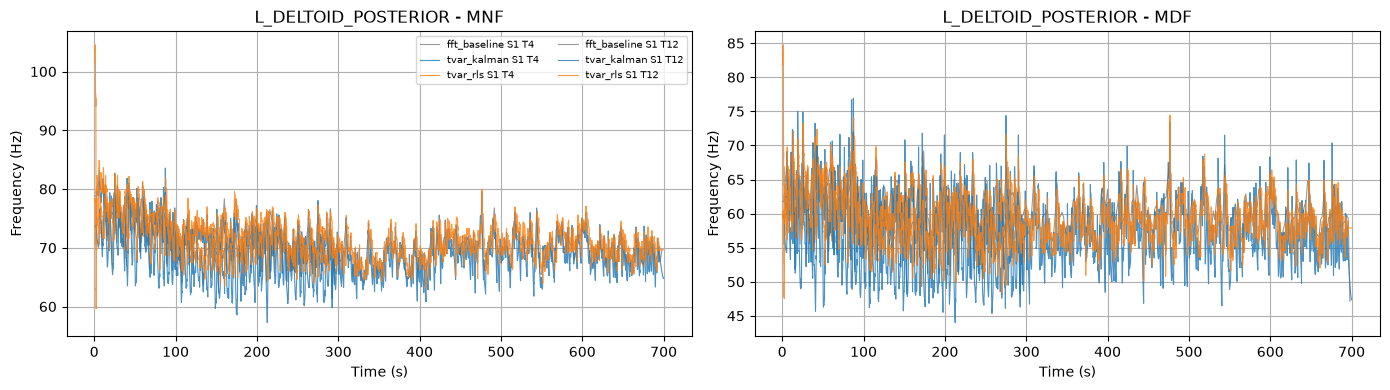

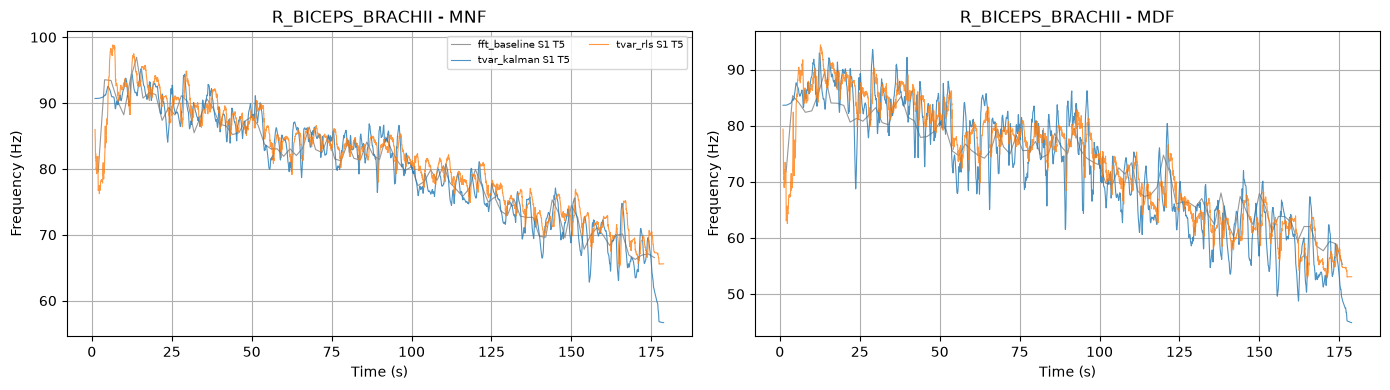

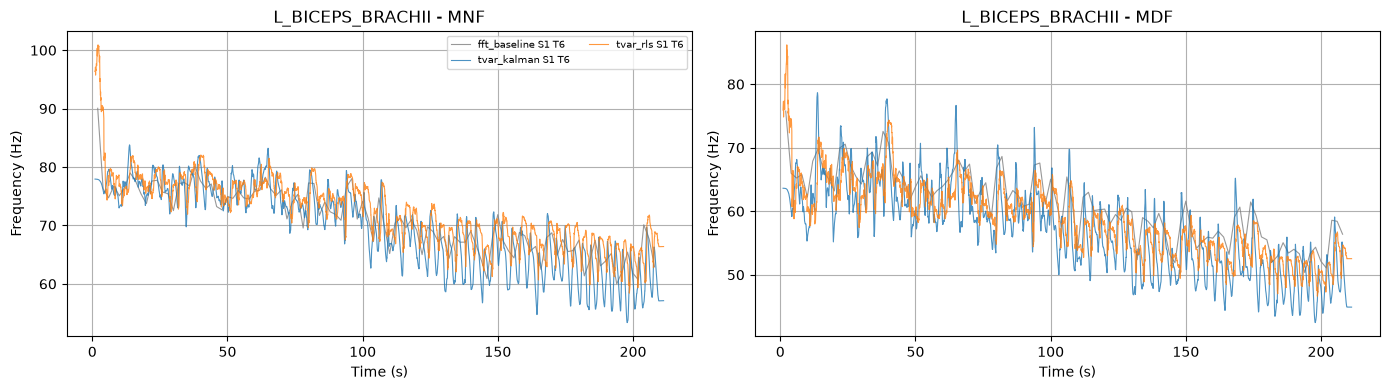

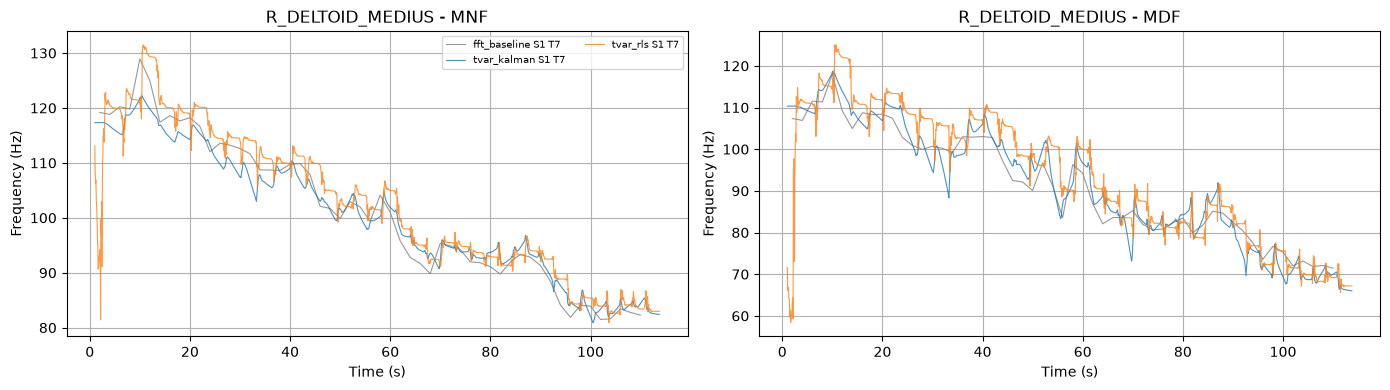

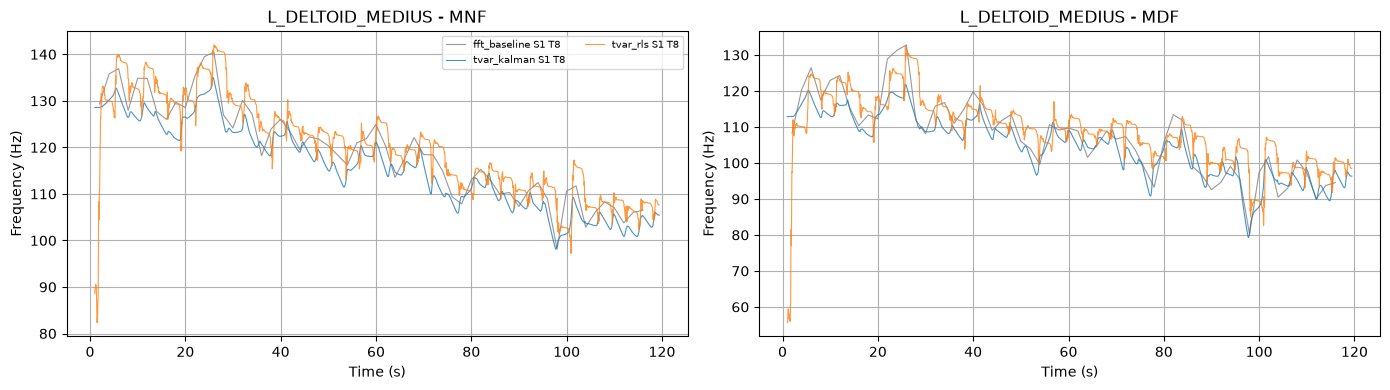

In [10]:
METHOD_COLORS = {"fft_baseline": "tab:gray", "tvar_kalman": "tab:blue", "tvar_rls": "tab:orange"}

for m in MUSCLES:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharex=True)
    for which, ax in zip(("mnf", "mdf"), axes):
        for s in SUBJECTS:
            for n, by_method in results[m][s].items():
                for method, track in by_method.items():
                    ax.plot(track.t, getattr(track, which), color=METHOD_COLORS[method], lw=0.8,
                            alpha=0.8, label=f"{method} S{s} T{n}")
        ax.set(title=f"{m} - {which.upper()}", xlabel="Time (s)", ylabel="Frequency (Hz)")
        ax.grid(True)
    axes[0].legend(fontsize=7, ncol=2)
    fig.tight_layout()
    plt.show()

In [0]:
# Trend SNR and roughness vs response time for every grid value, per muscle.
# The vertical line is the baseline's response time; the selected settings sit on it.
SWEEP = {m: {method: {v: [track_stats(align_to(run_tvar(tr, method, ORDER[m], **{key: v}), baseline[m][s][n]))
                          for s in SUBJECTS for n, tr in trials[m][s].items()]
                      for v in grid}
             for method, (key, grid) in GRIDS.items()}
         for m in MUSCLES}

for m in MUSCLES:
    base = stats_for(m, "fft_baseline")
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    for ax, metric in zip(axes, ("mnf_snr", "mnf_rough")):
        for method in GRIDS:
            pts = sorted((RISE[method][ORDER[m]][v], np.median([st[metric] for st in stats]))
                         for v, stats in SWEEP[m][method].items()
                         if np.isfinite(RISE[method][ORDER[m]][v]))
            ax.plot(*zip(*pts), "o-", ms=3, color=METHOD_COLORS[f"tvar_{method}"], label=f"tvar_{method}")
        ax.plot(TARGET_RT, np.median([st[metric] for st in base]), "*", ms=12,
                color=METHOD_COLORS["fft_baseline"], label="fft_baseline")
        ax.axvline(TARGET_RT, color="k", ls=":", lw=0.8)
        ax.set(xscale="log", xlabel="10-90 % rise time (s)", ylabel=metric, title=f"{m} - {metric}")
        ax.grid(True, which="both", alpha=0.3)
    axes[0].legend(fontsize=8)
    fig.tight_layout()
    plt.show()